# Multivariate UQ + cross-conditioning + inverse design

We fit a single `DifferentiableTreeRegressor` to a synthetic 2-output materials dataset,
then exercise three capabilities that fall out of the multivariate Gaussian-mixture
structure:

1. Joint marginal prediction $p(\mathbf{y} \mid \mathbf{x})$ with full covariance.
2. Cross-conditioning: $p(y_2 \mid \mathbf{x}, y_1)$ in closed form via Schur complements.
3. Inverse design: gradient-ascent over $\mathbf{x}$ to maximize $\log p(\mathbf{y}_{\text{target}} \mid \mathbf{x})$.

## Synthetic problem

Two correlated material properties depending on three composition variables. The
problem is set up so that $y_1$ and $y_2$ are non-trivially related through the inputs
(not via an additive correlation in the noise), exactly the regime where conditioning
should *tighten* uncertainty about $y_2$ once $y_1$ is observed.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from difftree import DifferentiableTreeRegressor

rng = np.random.default_rng(0)

In [ ]:
def true_means(X):
    x1, x2, x3 = X[:, 0], X[:, 1], X[:, 2]
    y1 = 1.5 + 0.8 * np.tanh(2.0 * x1 - x3) - 0.5 * x2
    y2 = 0.4 * y1 + 0.6 * np.cos(1.5 * x2) + 0.2 * x3
    return np.stack([y1, y2], axis=1)


def true_noise(Y_true):
    s1 = 0.05 + 0.10 * np.abs(Y_true[:, 0])
    s2 = 0.05 + 0.08 * np.abs(Y_true[:, 1])
    return np.stack([s1, s2], axis=1)


n = 1500
X = rng.uniform(-1.0, 1.0, (n, 3))
Y_true = true_means(X)
S_true = true_noise(Y_true)
Y = Y_true + rng.normal(0, S_true)

X_tr, X_te, Y_tr, Y_te = train_test_split(X, Y, test_size=300, random_state=0)
Yt_te = true_means(X_te)
St_te = true_noise(Yt_te)

print(f'train: {X_tr.shape[0]}, test: {X_te.shape[0]}')
print(f'y1 range: [{Y[:, 0].min():.2f}, {Y[:, 0].max():.2f}]')
print(f'y2 range: [{Y[:, 1].min():.2f}, {Y[:, 1].max():.2f}]')
print(f'corr(y1, y2): {np.corrcoef(Y_true[:, 0], Y_true[:, 1])[0, 1]:.3f}')

train: 1200, test: 300
y1 range: [0.15, 3.19]
y2 range: [0.04, 1.87]
corr(y1, y2): 0.747


## Fit

In [ ]:
model = DifferentiableTreeRegressor(
    depth=5, n_epochs=150, batch_size=256, learning_rate=0.01,
    gamma_max=5.0, delta_gamma=0.05,
    sigma_init=0.5, n_calibration_steps=300,
    random_state=0, verbose=True,
)
model.fit(X_tr, Y_tr)

[difftree] training on 1080 samples, d_y=2...
  [warmup] 38 epochs with frozen leaf variances


  [warmup] epoch    0  gamma= 1.00  loss=4.2043
  [warmup] epoch    3  gamma= 1.15  loss=3.4945
  [warmup] epoch    6  gamma= 1.30  loss=2.9042
  [warmup] epoch    9  gamma= 1.45  loss=2.3812
  [warmup] epoch   12  gamma= 1.60  loss=2.0483
  [warmup] epoch   15  gamma= 1.75  loss=1.8418
  [warmup] epoch   18  gamma= 1.90  loss=1.7423
  [warmup] epoch   21  gamma= 2.05  loss=1.5863
  [warmup] epoch   24  gamma= 2.20  loss=1.5007


  [warmup] epoch   27  gamma= 2.35  loss=1.4854
  [warmup] epoch   30  gamma= 2.50  loss=1.4221
  [warmup] epoch   33  gamma= 2.65  loss=1.3507
  [warmup] epoch   36  gamma= 2.80  loss=1.3322
  [warmup] epoch   37  gamma= 2.85  loss=1.3160


  [train] epoch    0  gamma= 2.90  loss=1.3541
  [train] epoch   11  gamma= 3.45  loss=1.0677
  [train] epoch   22  gamma= 4.00  loss=0.9085


  [train] epoch   33  gamma= 4.55  loss=0.7913
  [train] epoch   44  gamma= 5.00  loss=0.8039
  [train] epoch   55  gamma= 5.00  loss=0.7609


  [train] epoch   66  gamma= 5.00  loss=0.7531
  [train] epoch   77  gamma= 5.00  loss=0.7654
  [train] epoch   88  gamma= 5.00  loss=0.7435


  [train] epoch   99  gamma= 5.00  loss=0.7447
  [train] epoch  110  gamma= 5.00  loss=0.7480
  [train] epoch  111  gamma= 5.00  loss=0.7179
[difftree] calibrating on 120 held-out samples...


  calib step    0  val_nll=1.2589
  calib step   30  val_nll=1.1582
  calib step   60  val_nll=1.1500
  calib step   90  val_nll=1.1455
  calib step  120  val_nll=1.1449
  calib step  150  val_nll=1.1449
  calib step  180  val_nll=1.1449
  calib step  210  val_nll=1.1449
  calib step  240  val_nll=1.1449
  calib step  270  val_nll=1.1449
  calib step  299  val_nll=1.1449


,depth,5
,learning_rate,0.01
,batch_size,256
,n_epochs,150
,gamma_init,1.0
,gamma_max,5.0
,delta_gamma,0.05
,sigma_init,0.5
,warmup_fraction,0.25
,validation_fraction,0.1
,n_calibration_steps,300


## Marginal prediction with full covariance

The model returns a full 2x2 predictive covariance per sample. The off-diagonal
encodes the model's belief about how $y_1$ and $y_2$ co-vary at that input.

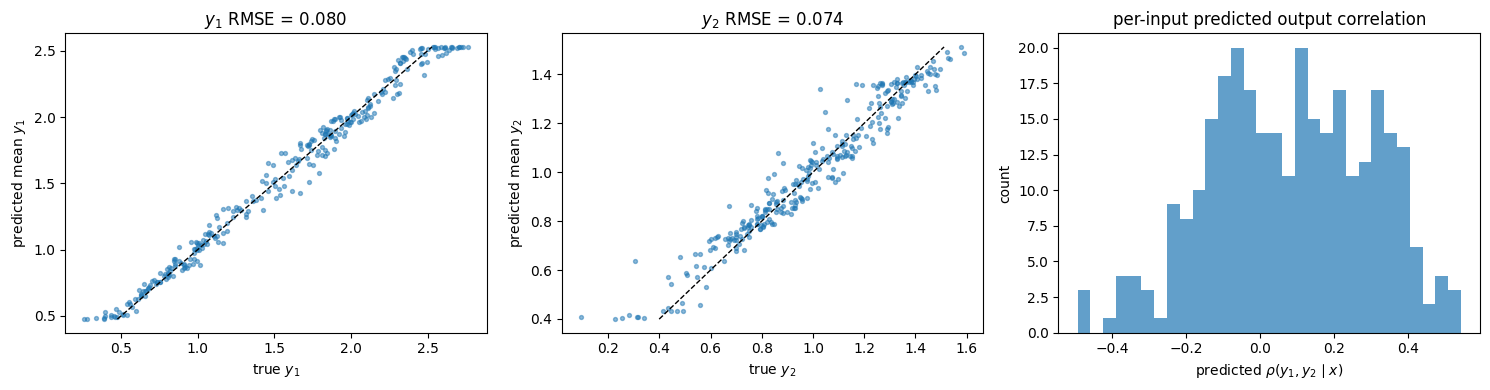

In [ ]:
Y_pred, cov_pred = model.predict_full_cov(X_te)
rho_pred = cov_pred[:, 0, 1] / np.sqrt(cov_pred[:, 0, 0] * cov_pred[:, 1, 1] + 1e-12)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, (ax, ylabel) in enumerate(zip(axes[:2], ['y_1', 'y_2'])):
    ax.scatter(Yt_te[:, i], Y_pred[:, i], s=8, alpha=0.5)
    lim = [Y_pred[:, i].min(), Y_pred[:, i].max()]
    ax.plot(lim, lim, 'k--', lw=1)
    ax.set_xlabel(f'true ${ylabel}$')
    ax.set_ylabel(f'predicted mean ${ylabel}$')
    rmse = float(np.sqrt(np.mean((Y_pred[:, i] - Yt_te[:, i]) ** 2)))
    ax.set_title(f'${ylabel}$ RMSE = {rmse:.3f}')

ax = axes[2]
ax.hist(rho_pred, bins=30, color='tab:blue', alpha=0.7)
ax.set_xlabel(r'predicted $\rho(y_1, y_2 \mid x)$')
ax.set_ylabel('count')
ax.set_title('per-input predicted output correlation')
plt.tight_layout()
plt.show()

## Cross-conditioning: knowing $y_1$ tightens uncertainty on $y_2$

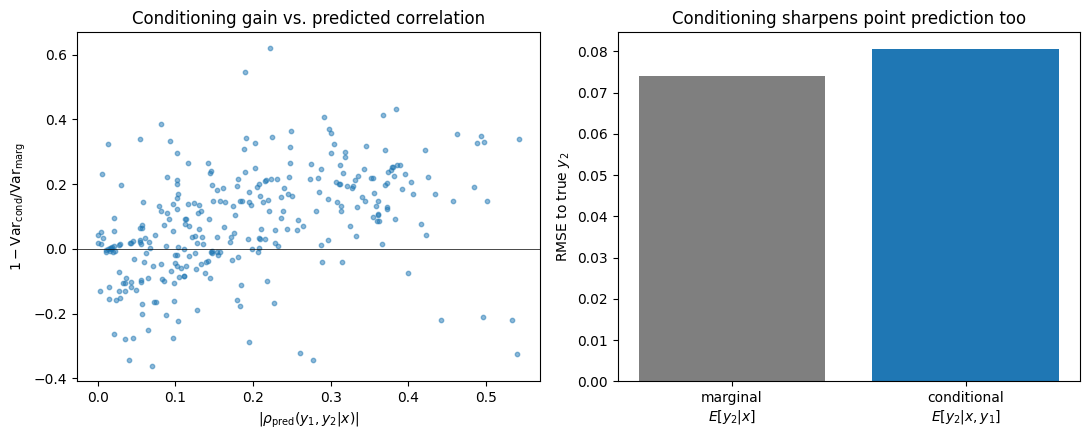

mean variance reduction: 0.078
RMSE marginal: 0.074
RMSE conditional: 0.081


In [ ]:
var_marg = cov_pred[:, 1, 1]
cond_mean, cond_cov, log_ev = model.predict_conditional(
    X_te, observed={0: Yt_te[:, 0]}
)
var_cond = cond_cov[:, 0, 0]
frac_kept = var_cond / np.maximum(var_marg, 1e-12)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ax = axes[0]
ax.scatter(np.abs(rho_pred), 1 - frac_kept, s=10, alpha=0.5)
ax.set_xlabel(r'$|\rho_{\mathrm{pred}}(y_1, y_2 | x)|$')
ax.set_ylabel(r'$1 - \mathrm{Var}_{\mathrm{cond}} / \mathrm{Var}_{\mathrm{marg}}$')
ax.set_title('Conditioning gain vs. predicted correlation')
ax.axhline(0, color='k', lw=0.5)

ax = axes[1]
rmse_marg = float(np.sqrt(np.mean((Y_pred[:, 1] - Yt_te[:, 1]) ** 2)))
rmse_cond = float(np.sqrt(np.mean((cond_mean[:, 0] - Yt_te[:, 1]) ** 2)))
ax.bar([0, 1], [rmse_marg, rmse_cond], color=['tab:gray', 'tab:blue'])
ax.set_xticks([0, 1])
ax.set_xticklabels(['marginal\n$E[y_2|x]$', 'conditional\n$E[y_2|x, y_1]$'])
ax.set_ylabel('RMSE to true $y_2$')
ax.set_title('Conditioning sharpens point prediction too')
plt.tight_layout()
plt.show()

print(f'mean variance reduction: {(1 - frac_kept).mean():.3f}')
print(f'RMSE marginal: {rmse_marg:.3f}')
print(f'RMSE conditional: {rmse_cond:.3f}')

## Inverse design: find $\mathbf{x}$ that produces a target $\mathbf{y}$

Pick a target property pair $(y_1^*, y_2^*)$ and ask: which composition $\mathbf{x}$
should we synthesize? We optimize $\log p(\mathbf{y}^* \mid \mathbf{x})$ by Adam ascent
over $\mathbf{x}$, with multiple random restarts to handle the multi-modal
log-likelihood surface. Because the tree is fully differentiable in $\mathbf{x}$, this is
just gradient descent: no surrogate, no MCMC.

In [ ]:
y_target = {0: 1.8, 1: 1.0}

x_best, ll_best, x_all, ll_all = model.inverse_design(
    y_target,
    n_starts=24, n_steps=600, learning_rate=0.05,
    bounds=(np.full(3, -1.0), np.full(3, 1.0)),
    random_state=0,
)

y_pred_best, std_best = model.predict(x_best.reshape(1, -1), return_std=True)
print(f'target            : y1={y_target[0]:.3f}, y2={y_target[1]:.3f}')
print(f'designed x        : {x_best.round(3)}')
print(f'predicted at best : y1={y_pred_best[0,0]:.3f} (+/-{std_best[0,0]:.3f}), '
      f'y2={y_pred_best[0,1]:.3f} (+/-{std_best[0,1]:.3f})')
print(f'log p(y* | x_best): {ll_best:.3f}')
print(f'top 5 restart log-liks: {sorted(ll_all)[-5:]}')

target            : y1=1.800, y2=1.000
designed x        : [1.    0.994 0.182]
predicted at best : y1=1.950 (+/-0.231), y2=0.955 (+/-0.159)
log p(y* | x_best): -0.056
top 5 restart log-liks: [np.float64(-0.05579432472586632), np.float64(-0.05579432472586632), np.float64(-0.05579432472586632), np.float64(-0.05579432472586632), np.float64(-0.05579432472586632)]


### Visualize the design landscape

Holding $x_3$ at the value found by inverse design, slice $\log p(\mathbf{y}^* \mid \mathbf{x})$
over $(x_1, x_2)$ and overlay the restart finals.

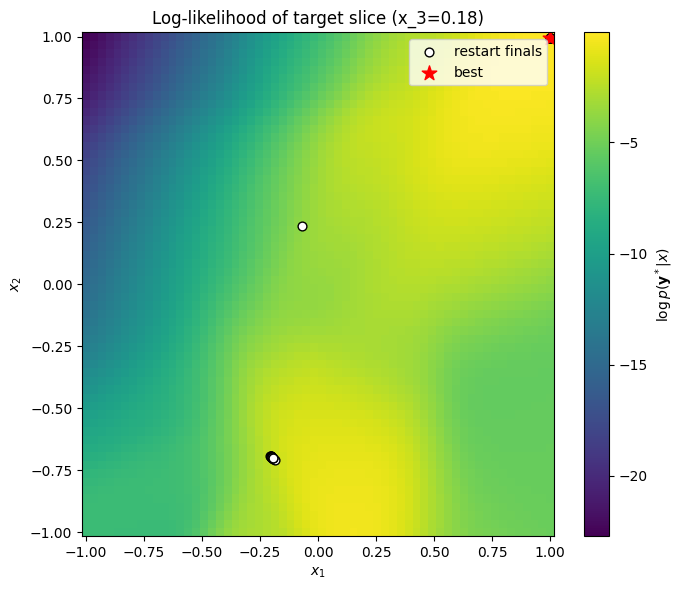

In [ ]:
import jax
import jax.numpy as jnp
from difftree._model import inverse_design_log_lik

params = model._params_jax()
obs_idx = jnp.asarray([0, 1], dtype=jnp.int32)
y_t = jnp.asarray((np.array([y_target[0], y_target[1]]) - model.y_mean_) / model.y_std_)

@jax.jit
def ll(x_std):
    return inverse_design_log_lik(
        x_std, y_t, obs_idx,
        params['W'], params['b'], params['log_gamma'],
        params['leaf_mu'], params['leaf_A'], params['leaf_chol_raw'], params['log_alpha'],
    )
ll_v = jax.vmap(ll)

x3_fixed = x_best[2]
g = np.linspace(-1.0, 1.0, 60)
X1, X2 = np.meshgrid(g, g)
Xg = np.stack([X1.ravel(), X2.ravel(), np.full(X1.size, x3_fixed)], axis=1)
Xg_std = (Xg - model.x_mean_) / model.x_std_
Lg = np.asarray(ll_v(jnp.asarray(Xg_std))).reshape(X1.shape)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.pcolormesh(X1, X2, Lg, cmap='viridis', shading='auto')
plt.colorbar(im, ax=ax, label=r'$\log p(\mathbf{y}^* | x)$')
ax.scatter(x_all[:, 0], x_all[:, 1], color='white', edgecolors='black',
           s=40, marker='o', label='restart finals')
ax.scatter([x_best[0]], [x_best[1]], color='red', s=120, marker='*', label='best')
ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')
ax.set_title(f'Log-likelihood of target slice (x_3={x3_fixed:.2f})')
ax.legend()
plt.tight_layout()
plt.show()

## Constrained inverse design: fix $y_1$, let $y_2$ float

Sometimes only one property is constrained. The inverse-design API takes a partial dict.

In [ ]:
x_best_c, ll_c, x_all_c, ll_all_c = model.inverse_design(
    {0: 1.8},
    n_starts=16, n_steps=500, learning_rate=0.05,
    bounds=(np.full(3, -1.0), np.full(3, 1.0)),
    random_state=1,
)

y_pred_c, std_c = model.predict(x_best_c.reshape(1, -1), return_std=True)
print(f'target y1={1.8:.3f} (y2 unconstrained)')
print(f'designed x: {x_best_c.round(3)}')
print(f'predicted: y1={y_pred_c[0,0]:.3f} (+/-{std_c[0,0]:.3f}),  '
      f'y2={y_pred_c[0,1]:.3f} (+/-{std_c[0,1]:.3f})')
print(f'log p(y1=1.8 | x): {ll_c:.3f}')

target y1=1.800 (y2 unconstrained)
designed x: [ 0.011 -0.307 -0.286]
predicted: y1=1.869 (+/-0.271),  y2=1.239 (+/-0.210)
log p(y1=1.8 | x): 0.311


## Summary

From a single fitted tree we get:

- **Joint marginal predictions** $p(\mathbf{y} \mid \mathbf{x})$ with full covariance,
  including a per-input predicted output correlation.
- **Closed-form cross-conditioning** $p(y_2 \mid \mathbf{x}, y_1)$ via Schur complements
  on each leaf's covariance, with leaf weights re-normalized by the marginal density of
  the observation. Knowing one output reduces the variance and RMSE on the other.
- **Differentiable inverse design**: the tree's likelihood
  $\log p(\mathbf{y}^* \mid \mathbf{x})$ is end-to-end differentiable in $\mathbf{x}$, so
  Adam ascent (with multi-start for multimodality) just works. Constrained variants
  where only a subset of outputs are targeted come for free.